# Word2Vec: CBOW vs Skip-Gram, Explanation and Implementation

## Real-life scenario: a synonym-aware search engine for an online store

You are an NLP engineer at **ShopSmart**, an e-commerce company. Customers type queries like

> *"cheap notebook for college"*

but the catalogue says

> *"budget laptop with fast processor and long battery for students"*

A keyword search finds **nothing in common** between the two ("cheap" is not "budget", "notebook" is not "laptop"). Your job: teach the machine that these words mean the same thing, using only the store's own reviews and product text, with no labelled data.

**Word2Vec** does exactly that. It learns a vector for every word so that words used in similar contexts get similar vectors.

### What this notebook does

1. Build a realistic corpus of product reviews and descriptions.
2. Preprocess it (tokenise, vocabulary, subsampling).
3. Implement **Skip-Gram** and **CBOW** with negative sampling **from scratch in NumPy**.
4. Compare them: quality, speed, rare words, window size.
5. Ship the feature: **query expansion and semantic product search**, compared against plain keyword matching.
6. Engineering checklist for production.

Only NumPy and matplotlib are required. `gensim` is used in an optional cell if installed. See `theory.md` for the theory.

## 1. Setup and the ShopSmart corpus

In [2]:
import re, time, random
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

np.set_printoptions(precision=3, suppress=True)
random.seed(7)

# ---- Synonym groups used by customers and sellers ----
price = ["cheap", "affordable", "budget"]
good  = ["excellent", "great", "amazing", "superb"]
bad   = ["terrible", "awful", "poor"]

# product concept -> (surface words people use, product-specific sentence templates)
products = {
  "laptop": (["laptop", "notebook"], [
      "the {w} has a fast processor and plenty of ram",
      "i use my {w} for coding and office work",
      "this {w} has a bright screen and a comfortable keyboard",
      "{price} {w} for students and college work",
      "the {w} battery lasts all day"]),
  "phone": (["phone", "smartphone", "mobile"], [
      "the {w} has an amazing camera and a sharp display",
      "i charge my {w} every night because the battery drains",
      "this {w} supports fast charging and has a big display",
      "{price} {w} with a good camera for photos",
      "my {w} runs apps smoothly and the battery lasts"]),
  "headphones": (["headphones", "earphones", "earbuds"], [
      "these {w} have deep bass and clear sound",
      "the {w} offer noise cancellation and wireless bluetooth",
      "i wear my {w} while running at the gym",
      "comfortable {w} with long battery for music",
      "{price} {w} with good sound for music lovers"]),
  "tv": (["television", "tv"], [
      "the {w} has a large screen and sharp resolution",
      "i stream movies on my {w} with a good remote",
      "this {w} supports hdmi and smart streaming apps",
      "{price} {w} for the living room and family movies",
      "the {w} sound and picture are clear"]),
  "shirt": (["shirt", "tshirt", "top"], [
      "this {w} is made of soft cotton fabric",
      "the {w} has short sleeves and a perfect size",
      "i wear this {w} to work and on weekends",
      "{price} {w} in many colors and sizes",
      "the {w} fabric is soft and breathable in summer"]),
  "jeans": (["jeans", "denim", "trousers"], [
      "these {w} have a slim fit and stretch fabric",
      "the {w} waist size is perfect",
      "i wear these {w} to work and on weekends",
      "{price} {w} in dark blue color",
      "the {w} are durable and comfortable for daily wear"]),
  "shoes": (["shoes", "sneakers", "footwear"], [
      "these {w} have a soft sole and good grip",
      "i wear my {w} for running and walking",
      "comfortable {w} with cushion for daily wear",
      "{price} {w} in many sizes and colors",
      "the {w} are lightweight and durable"]),
  "milk": (["milk", "dairy"], [
      "fresh {w} from the farm delivered every morning",
      "store the {w} in the fridge to keep it fresh",
      "{w} is rich in calcium and protein",
      "i drink {w} with breakfast every day",
      "{price} {w} pack for the family"]),
  "rice": (["rice", "grain"], [
      "the {w} cooks fast and tastes fluffy",
      "i cook {w} in the kitchen for dinner",
      "this {w} is aromatic and cooks fluffy",
      "{price} {w} pack for the family",
      "serve the {w} with curry and vegetables"]),
}

# generic review templates shared by every product (this is what ties synonyms like cheap/budget together)
generic = [
  "this {w} is {price} and the quality is {good}",
  "i love this {w} the value is {good}",
  "very {bad} {w} i want a refund",
  "the {w} is {good} and delivery was fast",
  "{bad} quality {w} do not buy",
]

def fill(t, w):
    return t.format(w=w, price=random.choice(price), good=random.choice(good), bad=random.choice(bad))

corpus = []
concepts = list(products)
for _ in range(4000):
    concept = random.choice(concepts)
    words, specific = products[concept]
    w = random.choice(words)
    t = random.choice(specific) if random.random() < 0.7 else random.choice(generic)
    corpus.append(fill(t, w))

# RARE words: a brand-new product word and a niche word, seen in only 8 sentences each
for rare, concept in [("ultrabook", "laptop"), ("basmati", "rice")]:
    for _ in range(8):
        corpus.append(fill(random.choice(products[concept][1]), rare))
random.shuffle(corpus)

print(len(corpus), "sentences")
for s in corpus[:6]:
    print(" -", s)

4016 sentences
 - cheap footwear in many sizes and colors
 - this grain is aromatic and cooks fluffy
 - very poor top i want a refund
 - affordable television for the living room and family movies
 - this shirt is made of soft cotton fabric
 - i cook basmati in the kitchen for dinner


## 2. Preprocessing

Steps every Word2Vec pipeline needs:

1. **Tokenise**: lowercase and split into words.
2. **Vocabulary with `min_count`**: very rare words give noisy vectors. (We keep words seen at least 5 times.)
3. **Subsampling of frequent words**: words like "the" carry little meaning and dominate the data. Each token is dropped with probability $1-\sqrt{t/f(w)}$.

In [3]:
def tokenize(s):
    return re.findall(r"[a-z]+", s.lower())

tokens_raw = [tokenize(s) for s in corpus]
counts_all = Counter(w for s in tokens_raw for w in s)

MIN_COUNT = 5
vocab = sorted(w for w, c in counts_all.items() if c >= MIN_COUNT)
w2i = {w: i for i, w in enumerate(vocab)}
i2w = {i: w for w, i in w2i.items()}
V = len(vocab)
counts = np.array([counts_all[w] for w in vocab], dtype=float)
total = counts.sum()
print("Vocabulary size:", V, "| tokens:", int(total))
print("Most common:", counts_all.most_common(6))
print("Rare words kept:", {w: counts_all[w] for w in ["ultrabook", "basmati"]})

# keep only in-vocab words
sentences = [[w for w in s if w in w2i] for s in tokens_raw]

def subsample(sentences, t=0.01, seed=0):
    r = np.random.default_rng(seed)
    freq = counts / total
    keep_p = np.minimum(1.0, np.sqrt(t / freq))          # P(keep) = sqrt(t/f)
    out = []
    for s in sentences:
        kept = [w for w in s if r.random() < keep_p[w2i[w]]]
        if len(kept) >= 2:
            out.append(kept)
    return out

train_sents = subsample(sentences)
kept = sum(len(s) for s in train_sents) / sum(len(s) for s in sentences)
print(f"Subsampling kept {kept:.0%} of tokens")
print("Example:", sentences[0], "->", train_sents[0])

Vocabulary size: 180 | tokens: 31857
Most common: [('and', 2258), ('the', 2220), ('is', 1305), ('i', 1051), ('a', 909), ('this', 855)]
Rare words kept: {'ultrabook': 8, 'basmati': 8}
Subsampling kept 84% of tokens
Example: ['cheap', 'footwear', 'in', 'many', 'sizes', 'and', 'colors'] -> ['cheap', 'footwear', 'in', 'many', 'sizes', 'colors']


## 3. Turning text into training examples

With window size $w$ every word becomes a **centre** and its $\pm w$ neighbours are its **context**. The two models slice the same window in opposite directions:

| | Input | Target | Examples per window |
|---|---|---|---|
| **Skip-Gram** | centre word | *each* context word | up to $2w$ (one per context word) |
| **CBOW** | all context words (averaged) | centre word | 1 |

Example for *"the budget laptop has a fast processor"*, centre = `laptop`, $w=2$:
- Skip-Gram: (laptop→the), (laptop→budget), (laptop→has), (laptop→a)
- CBOW: [the, budget, has, a] → laptop

In [4]:
def build_skipgram_pairs(sents, window=2):
    pairs = []
    for s in sents:
        ids = [w2i[w] for w in s]
        for i, c in enumerate(ids):
            for j in range(max(0, i - window), min(len(ids), i + window + 1)):
                if j != i:
                    pairs.append((c, ids[j]))
    return np.array(pairs, dtype=np.int64)

def build_cbow_examples(sents, window=2):
    ctxs, centers = [], []
    for s in sents:
        ids = [w2i[w] for w in s]
        for i, c in enumerate(ids):
            ctx = [ids[j] for j in range(max(0, i - window), min(len(ids), i + window + 1)) if j != i]
            ctx = ctx + [-1] * (2 * window - len(ctx))           # pad with -1
            ctxs.append(ctx); centers.append(c)
    return np.array(ctxs, dtype=np.int64), np.array(centers, dtype=np.int64)

W = 2
sg_pairs = build_skipgram_pairs(train_sents, W)
cb_ctx, cb_center = build_cbow_examples(train_sents, W)
print("Skip-Gram training pairs :", len(sg_pairs))
print("CBOW training examples   :", len(cb_center))
print("Skip-Gram makes ~%.1fx more updates per epoch than CBOW" % (len(sg_pairs) / len(cb_center)))
print()
print("Skip-Gram examples:", [(i2w[a], i2w[b]) for a, b in sg_pairs[:4]])
ex = [[i2w[i] for i in cb_ctx[5] if i >= 0], i2w[cb_center[5]]]
print("CBOW example      :", ex[0], "->", ex[1])

Skip-Gram training pairs : 82532
CBOW training examples   : 26657
Skip-Gram makes ~3.1x more updates per epoch than CBOW

Skip-Gram examples: [('cheap', 'footwear'), ('cheap', 'in'), ('footwear', 'cheap'), ('footwear', 'in')]
CBOW example      : ['many', 'sizes'] -> colors


## 4. Implementation: Skip-Gram with Negative Sampling (SGNS)

A full softmax over $V$ words is too slow for real vocabularies, so we turn it into **binary classification**: *is this (centre, context) pair real or random noise?*

$$\mathcal{L} = -\log\sigma(u_o^\top v_c) - \sum_{k=1}^{K}\log\sigma(-u_{n_k}^\top v_c)$$

Noise words $n_k$ are drawn from $P_n(w)\propto \text{count}(w)^{3/4}$. Two matrices are learned: `W_in` (the embeddings $v$) and `W_out` (context vectors $u$). Gradients with $p=\sigma(u\cdot v)$:

$$\frac{\partial\mathcal L}{\partial v_c}=\sum (p-y)\,u,\qquad \frac{\partial\mathcal L}{\partial u}=(p-y)\,v_c$$

The code is mini-batched and vectorised, so it trains in seconds.

In [5]:
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -30, 30)))

def noise_distribution():
    p = counts ** 0.75
    return p / p.sum()

def train_skipgram(pairs, dim=32, epochs=15, lr0=0.025, neg=5, batch=32, seed=0, verbose=True):
    r = np.random.default_rng(seed)
    W_in  = (r.random((V, dim)) - 0.5) / dim
    W_out = np.zeros((V, dim))
    neg_p = noise_distribution()
    n = len(pairs)
    steps_total = epochs * int(np.ceil(n / batch)); step = 0
    losses = []
    for ep in range(epochs):
        perm = r.permutation(n); ep_loss = 0.0
        for s in range(0, n, batch):
            idx = perm[s:s + batch]
            c, o = pairs[idx, 0], pairs[idx, 1]
            negs = r.choice(V, size=(len(idx), neg), p=neg_p)
            lr = max(lr0 * (1 - step / steps_total), lr0 * 0.01); step += 1

            v     = W_in[c]                                # (B, d)
            u_pos = W_out[o]                               # (B, d)
            u_neg = W_out[negs]                            # (B, K, d)
            p_pos = sigmoid((v * u_pos).sum(1))            # (B,)
            p_neg = sigmoid(np.einsum("bd,bkd->bk", v, u_neg))   # (B, K)
            ep_loss += (-np.log(p_pos + 1e-10) - np.log(1 - p_neg + 1e-10).sum(1)).sum()

            g_pos, g_neg = p_pos - 1.0, p_neg              # dL/dscore
            grad_v = g_pos[:, None] * u_pos + np.einsum("bk,bkd->bd", g_neg, u_neg)
            np.add.at(W_in,  c, -lr * grad_v)
            np.add.at(W_out, o, -lr * g_pos[:, None] * v)
            np.add.at(W_out, negs.ravel(), (-lr * g_neg[:, :, None] * v[:, None, :]).reshape(-1, dim))
        losses.append(ep_loss / n)
        if verbose: print(f"  epoch {ep+1:2d}/{epochs}  loss = {losses[-1]:.4f}")
    return W_in, W_out, losses

t0 = time.time()
print("Training Skip-Gram ...")
Wsg_in, Wsg_out, sg_losses = train_skipgram(sg_pairs)
sg_time = time.time() - t0
E_sg = Wsg_in + Wsg_out           # summing input and output vectors is a common, slightly better choice
print(f"Done in {sg_time:.1f}s")

Training Skip-Gram ...
  epoch  1/15  loss = 2.7206
  epoch  2/15  loss = 1.5893
  epoch  3/15  loss = 1.3558
  epoch  4/15  loss = 1.2999
  epoch  5/15  loss = 1.2731
  epoch  6/15  loss = 1.2595
  epoch  7/15  loss = 1.2497
  epoch  8/15  loss = 1.2372
  epoch  9/15  loss = 1.2257
  epoch 10/15  loss = 1.2249
  epoch 11/15  loss = 1.2182
  epoch 12/15  loss = 1.2105
  epoch 13/15  loss = 1.2018
  epoch 14/15  loss = 1.1991
  epoch 15/15  loss = 1.1917
Done in 14.4s


## 5. Implementation: CBOW with Negative Sampling

CBOW **averages** the context vectors into a hidden vector $h$ and asks the classifier whether the true centre word fits $h$:

$$h=\frac1{|C|}\sum_{c\in C}v_c,\qquad \mathcal L=-\log\sigma(u_{w}^\top h)-\sum_k\log\sigma(-u_{n_k}^\top h)$$

The gradient w.r.t. $h$ is shared equally among all context words. Because CBOW produces **one update per window** instead of one per context word, it is faster per epoch, but each context word gets a *diluted* signal.

In [6]:
def train_cbow(ctx, center, dim=32, epochs=15, lr0=0.05, neg=5, batch=32, seed=0, verbose=True):
    r = np.random.default_rng(seed)
    W_in  = (r.random((V, dim)) - 0.5) / dim
    W_out = np.zeros((V, dim))
    neg_p = noise_distribution()
    n = len(center)
    steps_total = epochs * int(np.ceil(n / batch)); step = 0
    losses = []
    for ep in range(epochs):
        perm = r.permutation(n); ep_loss = 0.0
        for s in range(0, n, batch):
            idx = perm[s:s + batch]
            cx, w = ctx[idx], center[idx]                      # (B, 2W), (B,)
            mask = (cx >= 0).astype(float)                     # (B, 2W)
            cnt = mask.sum(1, keepdims=True)                   # (B, 1)
            safe = np.where(cx >= 0, cx, 0)
            negs = r.choice(V, size=(len(idx), neg), p=neg_p)
            lr = max(lr0 * (1 - step / steps_total), lr0 * 0.01); step += 1

            h     = (W_in[safe] * mask[:, :, None]).sum(1) / cnt     # (B, d)  averaged context
            u_pos = W_out[w]
            u_neg = W_out[negs]
            p_pos = sigmoid((h * u_pos).sum(1))
            p_neg = sigmoid(np.einsum("bd,bkd->bk", h, u_neg))
            ep_loss += (-np.log(p_pos + 1e-10) - np.log(1 - p_neg + 1e-10).sum(1)).sum()

            g_pos, g_neg = p_pos - 1.0, p_neg
            grad_h = g_pos[:, None] * u_pos + np.einsum("bk,bkd->bd", g_neg, u_neg)   # (B, d)
            # share grad_h equally with each real context word
            share = (-lr * grad_h / cnt)[:, None, :] * mask[:, :, None]               # (B, 2W, d)
            np.add.at(W_in, safe.ravel(), share.reshape(-1, dim))
            np.add.at(W_out, w, -lr * g_pos[:, None] * h)
            np.add.at(W_out, negs.ravel(), (-lr * g_neg[:, :, None] * h[:, None, :]).reshape(-1, dim))
        losses.append(ep_loss / n)
        if verbose: print(f"  epoch {ep+1:2d}/{epochs}  loss = {losses[-1]:.4f}")
    return W_in, W_out, losses

t0 = time.time()
print("Training CBOW ...")
Wcb_in, Wcb_out, cb_losses = train_cbow(cb_ctx, cb_center)
cb_time = time.time() - t0
E_cb = Wcb_in + Wcb_out
print(f"Done in {cb_time:.1f}s")

Training CBOW ...
  epoch  1/15  loss = 3.0086
  epoch  2/15  loss = 1.7446
  epoch  3/15  loss = 1.0547
  epoch  4/15  loss = 0.7979
  epoch  5/15  loss = 0.6918
  epoch  6/15  loss = 0.6343
  epoch  7/15  loss = 0.5865
  epoch  8/15  loss = 0.5721
  epoch  9/15  loss = 0.5536
  epoch 10/15  loss = 0.5355
  epoch 11/15  loss = 0.5264
  epoch 12/15  loss = 0.5163
  epoch 13/15  loss = 0.5047
  epoch 14/15  loss = 0.4973
  epoch 15/15  loss = 0.4937
Done in 6.5s


## 6. Inspecting what the models learned

First the tools: cosine similarity and nearest neighbours. Then the question that matters for ShopSmart: *which words does the model think are synonyms of customers' query words?*

In [7]:
def normalize(M):
    return M / (np.linalg.norm(M, axis=1, keepdims=True) + 1e-12)

def nearest(word, E, k=5):
    En = normalize(E)
    sims = En @ En[w2i[word]]
    order = np.argsort(-sims)
    return [(i2w[i], round(float(sims[i]), 2)) for i in order if i != w2i[word]][:k]

for w in ["notebook", "cheap", "sneakers", "excellent", "ultrabook", "basmati"]:
    print(f"{w:10s}  SG  -> {nearest(w, E_sg, 3)}")
    print(f"{'':10s}  CBOW-> {nearest(w, E_cb, 3)}")

notebook    SG  -> [('laptop', 0.97), ('use', 0.76), ('ultrabook', 0.7)]
            CBOW-> [('laptop', 0.97), ('ultrabook', 0.71), ('students', 0.7)]
cheap       SG  -> [('affordable', 0.97), ('budget', 0.93), ('quality', 0.71)]
            CBOW-> [('affordable', 0.97), ('budget', 0.95), ('is', 0.72)]
sneakers    SG  -> [('shoes', 0.97), ('footwear', 0.96), ('lightweight', 0.67)]
            CBOW-> [('shoes', 0.95), ('footwear', 0.95), ('cushion', 0.63)]
excellent   SG  -> [('superb', 0.98), ('great', 0.96), ('quality', 0.79)]
            CBOW-> [('superb', 0.96), ('great', 0.96), ('is', 0.78)]
ultrabook   SG  -> [('coding', 0.83), ('office', 0.8), ('use', 0.8)]
            CBOW-> [('use', 0.73), ('laptop', 0.71), ('notebook', 0.71)]
basmati     SG  -> [('pack', 0.91), ('family', 0.79), ('grain', 0.75)]
            CBOW-> [('serve', 0.82), ('pack', 0.8), ('rice', 0.71)]


### Quantifying quality: synonym hit rate
We know the ground-truth synonym groups, so for every word we check whether **at least one true synonym is in its top-3 neighbours** (Hit@3).

In [8]:
synonym_groups = [v[0] for v in products.values()] + [price, good, bad]
synonym_groups = [[w for w in g if w in w2i] for g in synonym_groups]
synonym_groups = [g for g in synonym_groups if len(g) > 1]

def hit_rate(E, k=3, words=None):
    En = normalize(E)
    hits, total = 0, 0
    for g in synonym_groups:
        for w in g:
            if words is not None and w not in words: continue
            sims = En @ En[w2i[w]]
            top = [i2w[i] for i in np.argsort(-sims) if i != w2i[w]][:k]
            hits += any(s in top for s in g if s != w)
            total += 1
    return hits / max(total, 1)

print(f"Synonym Hit@3   Skip-Gram: {hit_rate(E_sg):.1%}    CBOW: {hit_rate(E_cb):.1%}")
print(f"Training time   Skip-Gram: {sg_time:.1f}s      CBOW: {cb_time:.1f}s  (same number of epochs)")

Synonym Hit@3   Skip-Gram: 100.0%    CBOW: 100.0%
Training time   Skip-Gram: 14.4s      CBOW: 6.5s  (same number of epochs)


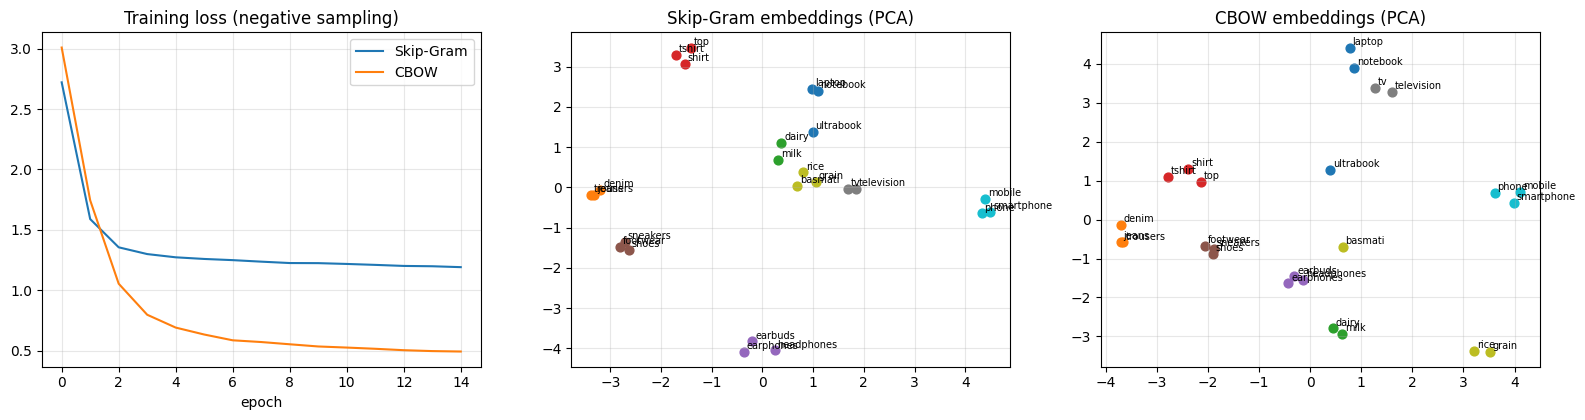

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))

# loss curves
axes[0].plot(sg_losses, label="Skip-Gram"); axes[0].plot(cb_losses, label="CBOW")
axes[0].set_title("Training loss (negative sampling)"); axes[0].set_xlabel("epoch"); axes[0].legend(); axes[0].grid(alpha=.3)

# 2-D PCA maps coloured by product family
family_color = {"laptop": "tab:blue", "phone": "tab:cyan", "headphones": "tab:purple", "tv": "tab:gray",
                "shirt": "tab:red", "jeans": "tab:orange", "shoes": "tab:brown", "milk": "tab:green", "rice": "tab:olive"}
extra = {"ultrabook": "laptop", "basmati": "rice"}
def pca_plot(ax, E, title):
    sel = [w for c, (ws, _) in products.items() for w in ws] + list(extra)
    X = E[[w2i[w] for w in sel]]
    X = X - X.mean(0)
    _, _, Vt = np.linalg.svd(X, full_matrices=False)
    X2 = X @ Vt[:2].T
    col = {w: family_color[c] for c, (ws, _) in products.items() for w in ws}
    col.update({w: family_color[c] for w, c in extra.items()})
    for (x, y), w in zip(X2, sel):
        ax.scatter(x, y, c=col[w], s=40); ax.annotate(w, (x, y), fontsize=7, xytext=(2, 2), textcoords="offset points")
    ax.set_title(title); ax.grid(alpha=.3)
pca_plot(axes[1], E_sg, "Skip-Gram embeddings (PCA)")
pca_plot(axes[2], E_cb, "CBOW embeddings (PCA)")
plt.tight_layout(); plt.show()

## 7. CBOW vs Skip-Gram: experiments

### 7.1 Rare words
The textbook argument: Skip-Gram creates a separate training example for every (centre, context) pair, so a rare word is trained **as the centre word many times**, while CBOW averages the context into one example and a rare word only gets a small share of each update. So Skip-Gram is *expected* to handle rare words better.

Let's test that claim instead of trusting it. `ultrabook` and `basmati` appear only 8 times each. We train both models with several random seeds and check how highly each ranks the true synonym (`laptop`/`notebook`, `rice`/`grain`); lower rank is better.

**Read the result honestly:** on this tiny, very regular corpus, CBOW can do just as well or better, because the sentence templates are repetitive and averaging the context is a good denoiser. The Skip-Gram advantage for rare words mostly shows up on large, messy, real-world corpora with a long tail of words. Always measure on *your* data.

In [10]:
def rank_of_synonyms(E, word, syns):
    En = normalize(E)
    sims = En @ En[w2i[word]]
    order = [i2w[i] for i in np.argsort(-sims) if i != w2i[word]]
    return min(order.index(s) + 1 for s in syns)           # best rank among the true synonyms

rare_tests = {"ultrabook": ["laptop", "notebook"], "basmati": ["rice", "grain"]}
res = {"Skip-Gram": {w: [] for w in rare_tests}, "CBOW": {w: [] for w in rare_tests}}
for seed in range(3):
    a, b, _ = train_skipgram(sg_pairs, seed=seed, verbose=False)
    c, d, _ = train_cbow(cb_ctx, cb_center, seed=seed, verbose=False)
    for w, syns in rare_tests.items():
        res["Skip-Gram"][w].append(rank_of_synonyms(a + b, w, syns))
        res["CBOW"][w].append(rank_of_synonyms(c + d, w, syns))

print("Rank of the true synonym among", V - 1, "words (1 = best), over 3 seeds")
for m in res:
    for w in rare_tests:
        print(f"  {m:10s} {w:10s} ranks = {res[m][w]}   mean = {np.mean(res[m][w]):.1f}")

Rank of the true synonym among 179 words (1 = best), over 3 seeds
  Skip-Gram  ultrabook  ranks = [4, 4, 4]   mean = 4.0
  Skip-Gram  basmati    ranks = [3, 3, 3]   mean = 3.0
  CBOW       ultrabook  ranks = [2, 2, 2]   mean = 2.0
  CBOW       basmati    ranks = [3, 3, 2]   mean = 2.7


### 7.2 Window size
Small windows capture *functional / syntactic* similarity (words that can replace each other). Large windows capture *topical* similarity (words that appear in the same kind of text).

In [11]:
print("Skip-Gram, effect of window size")
print(f"{'window':>6s}  {'pairs':>8s}  {'Hit@3':>7s}   neighbours of 'laptop'")
for win in [1, 2, 4]:
    pr = build_skipgram_pairs(train_sents, win)
    a, b, _ = train_skipgram(pr, epochs=8, verbose=False)
    E = a + b
    print(f"{win:6d}  {len(pr):8d}  {hit_rate(E):7.1%}   {[w for w, _ in nearest('laptop', E, 4)]}")

Skip-Gram, effect of window size
window     pairs    Hit@3   neighbours of 'laptop'
     1     45282   100.0%   ['notebook', 'television', 'tv', 'for']
     2     82532   100.0%   ['notebook', 'use', 'ultrabook', 'coding']
     4    132940   100.0%   ['notebook', 'ultrabook', 'use', 'office']


### 7.3 Summary

| Aspect | Skip-Gram | CBOW |
|---|---|---|
| Direction | centre → context | context → centre |
| Updates per window | up to $2w$ | 1 |
| Time per epoch | slower | faster |
| Rare words | often better on large real corpora | often weaker on large real corpora (see 7.1 for a toy counter-example) |
| Frequent words | good | very good, smooth |
| Best for | small/medium data, rare words, product names | huge corpora, speed |
| Typical learning rate | 0.025 | 0.05 |

## 8. Shipping the feature: query expansion and semantic product search

Now the payoff. We add two features to ShopSmart search:

1. **Query expansion**: for each query word, add its nearest neighbours.
2. **Semantic ranking**: represent every product and query as the **IDF-weighted average of their word vectors**, then rank by cosine similarity.

We compare against a plain **keyword-overlap** baseline.

In [12]:
catalog = [
  "budget notebook with fast processor and long battery for students",
  "premium laptop with bright screen and plenty of ram for coding",
  "affordable smartphone with amazing camera and fast charging",
  "mobile with big display and long battery",
  "wireless earbuds with deep bass and noise cancellation",
  "cheap headphones with clear sound for running",
  "television with large screen and sharp resolution for movies",
  "budget tv with hdmi and smart streaming apps",
  "soft cotton tshirt with short sleeves in many sizes",
  "slim fit denim with stretch fabric and perfect waist",
  "lightweight sneakers with soft sole for running",
  "comfortable footwear with cushion for daily wear",
  "fresh dairy pack rich in calcium for the family",
  "aromatic basmati cooks fluffy for dinner",
  "affordable rice pack for the family kitchen",
  "great milk from the farm delivered every morning",
]

stop = set("a an the and with for of in on at by to is are my i this these from it".split())
def content_words(text):
    return [w for w in tokenize(text) if w not in stop]

# IDF from the review corpus: rare words are more informative
df = Counter(w for s in sentences for w in set(s))
idf = {w: np.log(len(sentences) / (1 + df[w])) + 1 for w in vocab}

def embed_text(text, E):
    En = normalize(E)
    ws = [w for w in content_words(text) if w in w2i]
    if not ws: return np.zeros(E.shape[1])
    v = sum(idf[w] * En[w2i[w]] for w in ws)
    return v / (np.linalg.norm(v) + 1e-12)

def keyword_search(query, k=3):
    q = set(content_words(query))
    scored = [(len(q & set(content_words(d))), d) for d in catalog]
    scored.sort(key=lambda x: -x[0])
    return [(s, d) for s, d in scored[:k]]

def semantic_search(query, E, k=3):
    D = np.stack([embed_text(d, E) for d in catalog])
    sims = D @ embed_text(query, E)
    return [(round(float(sims[i]), 2), catalog[i]) for i in np.argsort(-sims)[:k]]

def expand_query(query, E, per_word=3, min_sim=0.8):
    # add close neighbours only: skip stop-words and weak matches
    out = []
    for w in content_words(query):
        if w in w2i:
            out += [n for n, sim in nearest(w, E, per_word) if sim >= min_sim and n not in stop]
    return out

In [13]:
queries = [
  "cheap notebook for college",
  "affordable mobile with great camera",
  "earphones for the gym",
  "trousers for work",
  "cheap footwear for walking",
  "tv for family movies",
]
for q in queries:
    print("QUERY:", q)
    print("  expansion (Skip-Gram):", expand_query(q, E_sg))
    kw = keyword_search(q, 1)[0]
    print(f"  keyword match -> overlap={kw[0]}: {kw[1] if kw[0] else '(no results)'}")
    s = semantic_search(q, E_sg, 1)[0]
    print(f"  semantic top1 -> score={s[0]}: {s[1]}")
    print()

QUERY: cheap notebook for college
  expansion (Skip-Gram): ['affordable', 'budget', 'laptop', 'students', 'office', 'coding']
  keyword match -> overlap=1: budget notebook with fast processor and long battery for students
  semantic top1 -> score=0.75: budget notebook with fast processor and long battery for students

QUERY: affordable mobile with great camera
  expansion (Skip-Gram): ['cheap', 'budget', 'smartphone', 'phone', 'superb', 'excellent', 'photos']
  keyword match -> overlap=2: affordable smartphone with amazing camera and fast charging
  semantic top1 -> score=0.83: affordable smartphone with amazing camera and fast charging

QUERY: earphones for the gym
  expansion (Skip-Gram): ['headphones', 'earbuds', 'running']
  keyword match -> overlap=0: (no results)
  semantic top1 -> score=0.7: cheap headphones with clear sound for running

QUERY: trousers for work
  expansion (Skip-Gram): ['jeans', 'denim', 'weekends']
  keyword match -> overlap=0: (no results)
  semantic top1 -> 

### Evaluate the search properly
We label which catalogue items are relevant to each query and compute **Recall@1**: does the top result belong to the right product family?

Look at the failure case printed at the end. The query "tv for family movies" is short, and `family` is a *generic* word that, in our reviews, appears in food contexts (`pack for the family`) as often as in TV contexts. Averaging word vectors lets that generic word pull the query toward groceries. This is a real, common weakness of averaged embeddings. In production you would address it with domain stop-words, field weighting, more data, or by using embeddings only as *one signal* in a ranker rather than the whole search engine.

In [14]:
relevant = {   # query -> set of catalogue indices that are correct answers
  "cheap notebook for college":            {0, 1},
  "affordable mobile with great camera":   {2, 3},
  "earphones for the gym":                 {4, 5},
  "trousers for work":                     {9},
  "cheap footwear for walking":            {10, 11},
  "tv for family movies":                  {6, 7},
}
def top1_correct(search_fn):
    ok = 0
    for q, rel in relevant.items():
        top = search_fn(q)
        ok += catalog.index(top) in rel
    return ok / len(relevant)

kw_top = lambda q: (keyword_search(q, 1)[0][1] if keyword_search(q, 1)[0][0] > 0 else "")
def sem_top(E): return lambda q: semantic_search(q, E, 1)[0][1]

def kw_ok(q): 
    t = kw_top(q); return t != "" and catalog.index(t) in relevant[q]
kw_recall = np.mean([kw_ok(q) for q in relevant])
print(f"Keyword baseline Recall@1 : {kw_recall:.0%}")
print(f"Semantic (Skip-Gram)      : {top1_correct(sem_top(E_sg)):.0%}")
print(f"Semantic (CBOW)           : {top1_correct(sem_top(E_cb)):.0%}")

# a failure case worth inspecting
q = "tv for family movies"
print()
print("Inspecting the failure case:", q)
for score, d in semantic_search(q, E_sg, 3):
    print(f"  {score:5.2f}  {d}")
print("\nQuery words in the model's eyes:")
for w in content_words(q):
    print(f"  {w:8s} -> {[n for n, _ in nearest(w, E_sg, 4)]}")

Keyword baseline Recall@1 : 50%
Semantic (Skip-Gram)      : 83%
Semantic (CBOW)           : 67%

Inspecting the failure case: tv for family movies
   0.44  affordable rice pack for the family kitchen
   0.28  budget tv with hdmi and smart streaming apps
   0.24  fresh dairy pack rich in calcium for the family

Query words in the model's eyes:
  tv       -> ['television', 'living', 'supports', 'large']
  family   -> ['room', 'pack', 'living', 'basmati']
  movies   -> ['stream', 'on', 'room', 'family']


## 9. Optional: the production library (`gensim`)
In real projects you rarely hand-write Word2Vec. `gensim` implements both models in optimised C and supports `sg=1` (Skip-Gram) / `sg=0` (CBOW).

In [15]:
try:
    from gensim.models import Word2Vec
    sents = [s for s in sentences]
    for name, sg in [("Skip-Gram", 1), ("CBOW", 0)]:
        m = Word2Vec(sents, vector_size=32, window=2, min_count=5, sg=sg, negative=5,
                     sample=1e-2, epochs=30, seed=1, workers=1)
        print(name, "| notebook ->", [w for w, _ in m.wv.most_similar("notebook", topn=3)],
              "| cheap ->", [w for w, _ in m.wv.most_similar("cheap", topn=3)])
except ImportError:
    print("gensim is not installed. Run `pip install gensim` to try the production implementation.")

Skip-Gram | notebook -> ['laptop', 'ultrabook', 'tv'] | cheap -> ['affordable', 'budget', 'great']
CBOW | notebook -> ['laptop', 'tv', 'ultrabook'] | cheap -> ['affordable', 'budget', 'excellent']


## 10. NLP-engineering checklist for production

**Data**
- Train on **in-domain text** (your own reviews, tickets, queries). A model trained on Wikipedia knows nothing about your product names.
- Normalise consistently between training and serving (case, punctuation, unicode, spelling).
- Use `min_count` of 5 to 20 on real corpora; handle the rest as out-of-vocabulary.

**Hyper-parameters (good starting points)**

| Parameter | Typical value | Notes |
|---|---|---|
| `vector_size` | 100 to 300 | 32 is enough for this toy corpus |
| `window` | 5 (Skip-Gram), 5 to 10 (CBOW) | small = similar function, large = similar topic |
| `negative` | 5 to 20 small data, 2 to 5 big data | |
| `sample` (subsampling) | 1e-3 to 1e-5 | we used 1e-2 because our corpus is tiny |
| `epochs` | 5 to 30 | more for small data |
| `alpha` | 0.025 (SG) / 0.05 (CBOW) | linearly decayed |

**Serving**
- Persist the matrix (`np.save`) and the vocabulary together. Version both.
- Handle OOV words: skip them, fall back to keyword search, or use **FastText** (subword vectors).
- Pre-compute product vectors offline and use an approximate nearest-neighbour index (FAISS, ScaNN, HNSW) at query time.

**Monitoring and evaluation**
- Offline: synonym Hit@k, word-similarity benchmarks, search Recall@k on labelled queries.
- Online: click-through rate, zero-result rate, query reformulation rate.
- Re-train when vocabulary drifts (new products, slang, seasonal terms).

**Know the limits**
- One vector per word: "apple" (fruit) and "apple" (phone) share a vector. Contextual models (BERT and relatives) fix this.
- Embeddings inherit biases from the training text. Audit before using them in ranking or decisions that affect people.

## Key takeaways

1. Word2Vec learns word meaning from **co-occurrence in context**, with no labels.
2. **Skip-Gram** predicts the context from a word: more training signal per word, generally recommended for **rare words** and smaller corpora, slower.
3. **CBOW** predicts a word from its averaged context: faster, smoother, good for **frequent words** and huge corpora.
4. **Negative sampling** turns an expensive $V$-way softmax into a handful of binary classifications.
5. In the ShopSmart example, a few thousand reviews were enough to make "notebook" and "laptop" interchangeable in search, something keyword matching can never do.